In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
try:
    import shap
    print("SHAP version:", shap.__version__)
    print("SHAP library imported successfully!")
except ImportError:
    print("SHAP library is not installed.")

SHAP version: 0.54.1
SHAP library imported successfully!


In [3]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [4]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP library imported successfully!")

SHAP version: 0.54.1
SHAP library imported successfully!


In [5]:
from pathlib import Path
import joblib

PROJECT_DIR = Path.cwd().parent

models_dir = PROJECT_DIR / "models"

success_model = joblib.load(models_dir / "success_model.pkl")
success_preprocessor = joblib.load(models_dir / "success_preprocessor.pkl")

print("Success model loaded:", type(success_model).__name__)
print("Preprocessor loaded:", type(success_preprocessor).__name__)
print("Models directory:", models_dir)

Success model loaded: GradientBoostingClassifier
Preprocessor loaded: ColumnTransformer
Models directory: c:\Users\ASUS\Desktop\AI Marketing Campaign\models


In [6]:
# Load the cleaned dataset
data_path = PROJECT_DIR / "data" / "clean" / "cleaned_data.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Profit column exists:", "profit" in df.columns)

Dataset loaded successfully!
Dataset shape: (10000, 42)
Profit column exists: True


In [7]:
# Check available columns in the cleaned dataset
print("Dataset columns:")
print(df.columns.tolist())

print("\nDoes campaign_success exist?", "campaign_success" in df.columns)
print("Does profit exist?", "profit" in df.columns)

Dataset columns:
['campaign_objective', 'platform', 'ad_placement', 'device_type', 'operating_system', 'creative_format', 'creative_size', 'ad_copy_length', 'has_call_to_action', 'creative_emotion', 'creative_age_days', 'target_audience_age', 'target_audience_gender', 'audience_interest_category', 'income_bracket', 'purchase_intent_score', 'retargeting_flag', 'quarter', 'day_of_week', 'hour_of_day', 'campaign_day', 'quality_score', 'actual_cpc', 'impressions', 'clicks', 'conversions', 'ad_spend', 'revenue', 'bounce_rate', 'avg_session_duration_seconds', 'pages_per_session', 'industry_vertical', 'budget_tier', 'CTR', 'CPC', 'conversion_rate', 'CPA', 'ROAS', 'profit', 'start_year', 'start_month', 'start_day']

Does campaign_success exist? False
Does profit exist? True


In [8]:
# Create campaign success target using the same definition
target = "campaign_success"

df[target] = (df["profit"] > 0).astype(int)

# Remove target and leakage-related columns from features
leakage_columns = [
    "campaign_success",
    "profit",
    "revenue",
    "ad_spend",
    "ROAS",
    "CTR",
    "CPC",
    "conversion_rate",
    "CPA",
    "clicks",
    "conversions",
]

X = df.drop(columns=leakage_columns, errors="ignore")
X = X.drop(columns=["campaign_id"], errors="ignore")
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Features shape: (10000, 32)
Target shape: (10000,)

Target distribution:
campaign_success
1    7831
0    2169
Name: count, dtype: int64

Target percentage:
campaign_success
1    78.31
0    21.69
Name: proportion, dtype: float64


In [9]:
print("Preprocessor transformers:")
print(success_preprocessor.transformers_)

print("\nPreprocessor feature names available:")
try:
    feature_names = success_preprocessor.get_feature_names_out()
    print("Total processed features:", len(feature_names))
    print(feature_names[:20])
except Exception as e:
    print("Could not retrieve feature names:", e)

Preprocessor transformers:
[('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), ['creative_age_days', 'quarter', 'hour_of_day', 'campaign_day', 'quality_score', 'actual_cpc', 'impressions', 'bounce_rate', 'avg_session_duration_seconds', 'pages_per_session', 'start_year', 'start_month', 'start_day']), ('cat', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))]), ['campaign_objective', 'platform', 'ad_placement', 'device_type', 'operating_system', 'creative_format', 'creative_size', 'ad_copy_length', 'has_call_to_action', 'creative_emotion', 'target_audience_age', 'target_audience_gender', 'audience_interest_category', 'income_bracket', 'purchase_intent_score', 'retargeting_flag', 'day_of_week', 'industry_vertical', 'budget_tier'])]

Preprocessor feature names available:
Total processed features: 101
['num__creative_age_days' 'num__quar

In [10]:
# Transform the original features using the saved preprocessor
X_processed = success_preprocessor.transform(X)

# Convert to dense array if the output is sparse
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

feature_names = success_preprocessor.get_feature_names_out()

X_processed_df = pd.DataFrame(
    X_processed,
    columns=feature_names,
    index=X.index
)

print("Processed dataset shape:", X_processed_df.shape)
print("Model expected features:", success_model.n_features_in_)
print("Processed feature names:", len(feature_names))

Processed dataset shape: (10000, 101)
Model expected features: 101
Processed feature names: 101


In [11]:
# Use a small background sample for SHAP
background = X_processed_df.sample(n=100, random_state=42)

# Explain a sample of campaigns first
X_explain = X_processed_df.sample(n=200, random_state=42)

explainer = shap.Explainer(
    success_model,
    background
)

shap_values = explainer(X_explain)

print("SHAP explainer created successfully!")
print("Explained campaigns:", X_explain.shape[0])
print("SHAP values shape:", shap_values.values.shape)

SHAP explainer created successfully!
Explained campaigns: 200
SHAP values shape: (200, 101)


,Feature,Mean_Absolute_SHAP
7,num__bounce_rate,0.6093
30,cat__device_type_Desktop,0.4947
5,num__actual_cpc,0.4647
14,cat__campaign_objective_Brand Awareness,0.2601
6,num__impressions,0.2194
92,cat__industry_vertical_E-commerce,0.2149
3,num__campaign_day,0.1900
43,cat__creative_format_Video,0.1897
78,cat__income_bracket_<$50K,0.1871
83,cat__retargeting_flag_False,0.1590


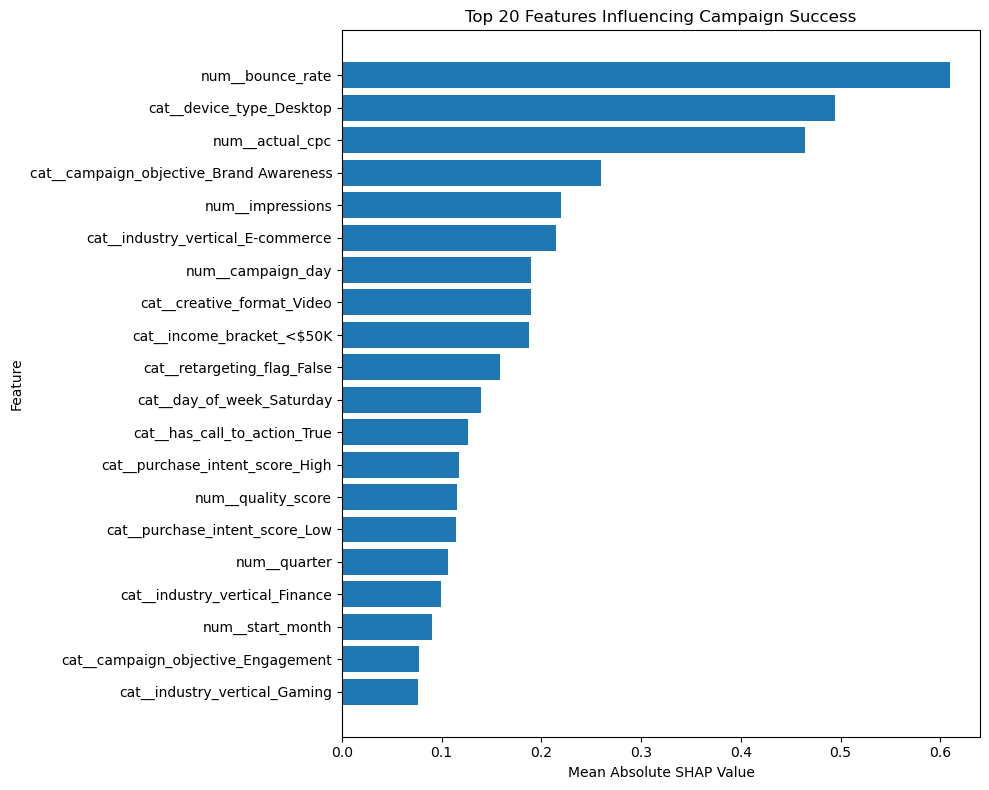

In [12]:
# Calculate mean absolute SHAP value for each feature
shap_importance = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

# Display top 20 important features
display(shap_importance.head(20).round(4))

# Plot top 20 features
top_features = shap_importance.head(20).sort_values(
    by="Mean_Absolute_SHAP"
)

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 20 Features Influencing Campaign Success")
plt.tight_layout()
plt.show()

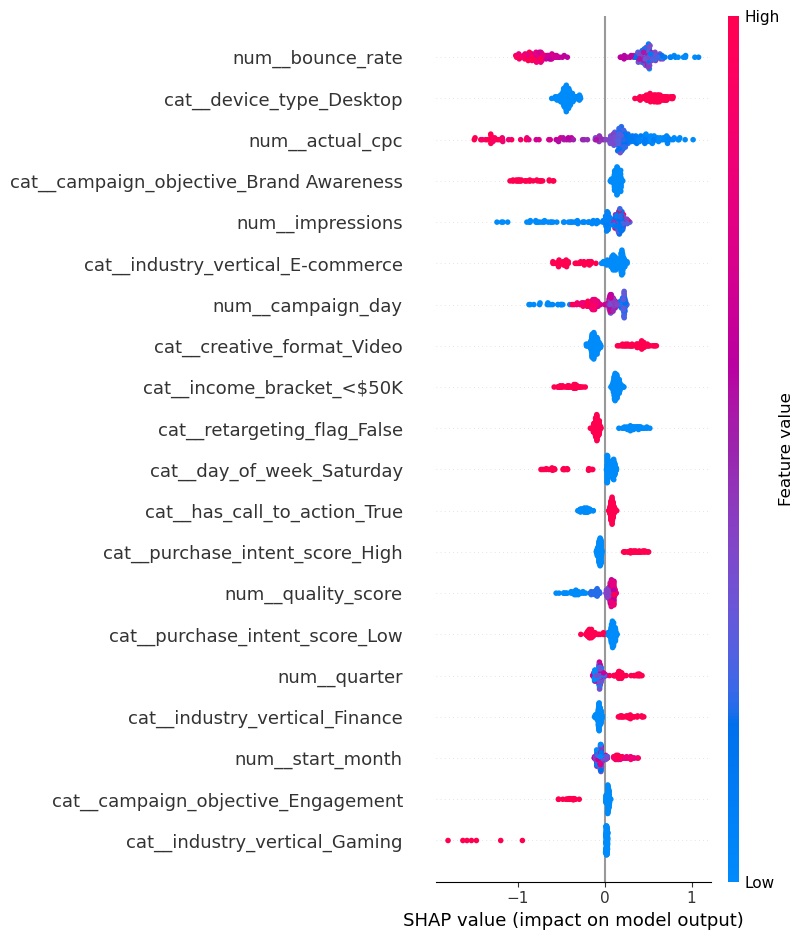

In [13]:
# SHAP summary plot for all processed features
shap.summary_plot(
    shap_values.values,
    X_explain,
    max_display=20,
    show=True
)

In [14]:
# Explain the first campaign in our SHAP sample
campaign_index = 0

campaign_shap = shap_values[campaign_index]

print("Campaign index:", X_explain.index[campaign_index])
print("Predicted class:", success_model.predict(
    X_processed_df.loc[[X_explain.index[campaign_index]]]
)[0])
print("Actual class:", y.loc[X_explain.index[campaign_index]])

Campaign index: 6252
Predicted class: 0
Actual class: 1


c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(


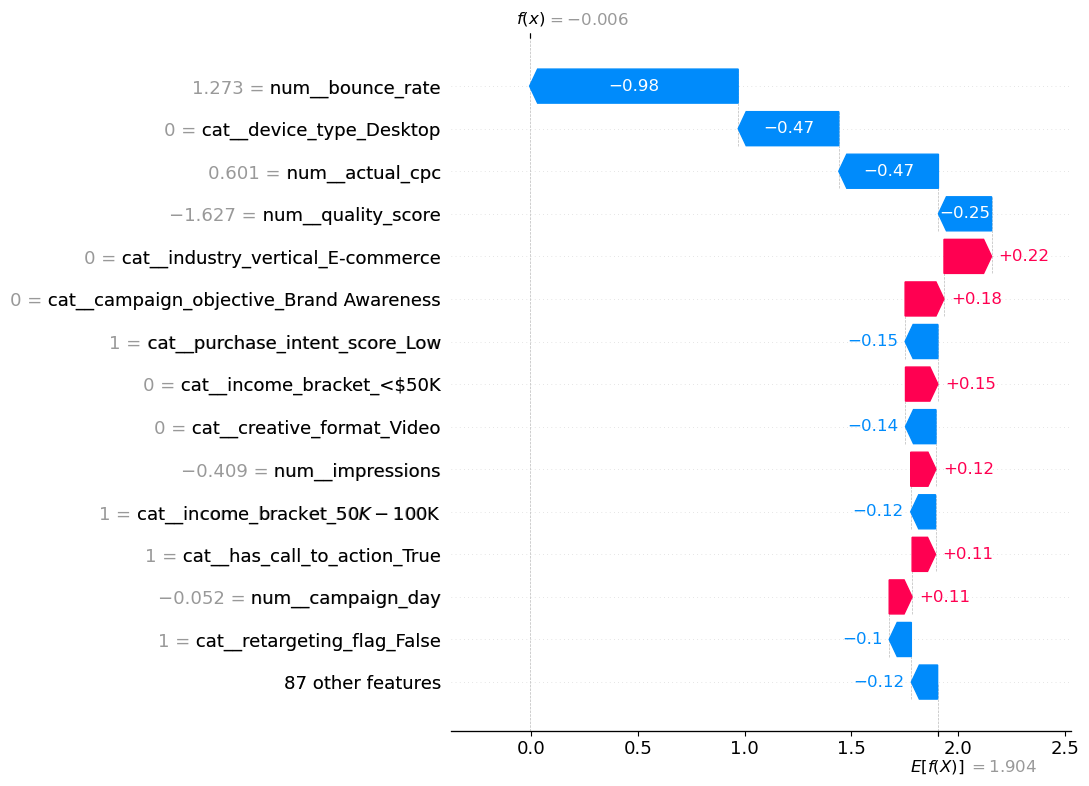

In [15]:
# Waterfall plot explaining this campaign's prediction
shap.plots.waterfall(campaign_shap, max_display=15)

In [16]:
# Create a readable explanation for this campaign
campaign_explanation = pd.DataFrame({
    "Feature": X_explain.columns,
    "Feature_Value": X_explain.iloc[campaign_index].values,
    "SHAP_Value": shap_values.values[campaign_index]
})

campaign_explanation["Absolute_SHAP"] = (
    campaign_explanation["SHAP_Value"].abs()
)

campaign_explanation = campaign_explanation.sort_values(
    by="Absolute_SHAP",
    ascending=False
)

display(campaign_explanation.head(15).round(4))

,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
7,num__bounce_rate,1.2728,-0.9766,0.9766
30,cat__device_type_Desktop,0.0000,-0.4710,0.4710
5,num__actual_cpc,0.6009,-0.4666,0.4666
4,num__quality_score,-1.6269,-0.2489,0.2489
92,cat__industry_vertical_E-commerce,0.0000,0.2229,0.2229
14,cat__campaign_objective_Brand Awareness,0.0000,0.1820,0.1820
81,cat__purchase_intent_score_Low,1.0000,-0.1535,0.1535
78,cat__income_bracket_<$50K,0.0000,0.1517,0.1517
43,cat__creative_format_Video,0.0000,-0.1427,0.1427
6,num__impressions,-0.4086,0.1183,0.1183


In [17]:
# Create results directory
results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Save global SHAP feature importance
global_path = results_dir / "success_shap_feature_importance.csv"
shap_importance.to_csv(global_path, index=False)

# Save individual campaign explanation
individual_path = results_dir / "success_shap_campaign_6252.csv"
campaign_explanation.to_csv(individual_path, index=False)

print("SHAP results saved successfully!")
print("Global importance:", global_path)
print("Individual explanation:", individual_path)

SHAP results saved successfully!
Global importance: c:\Users\ASUS\Desktop\AI Marketing Campaign\results\success_shap_feature_importance.csv
Individual explanation: c:\Users\ASUS\Desktop\AI Marketing Campaign\results\success_shap_campaign_6252.csv


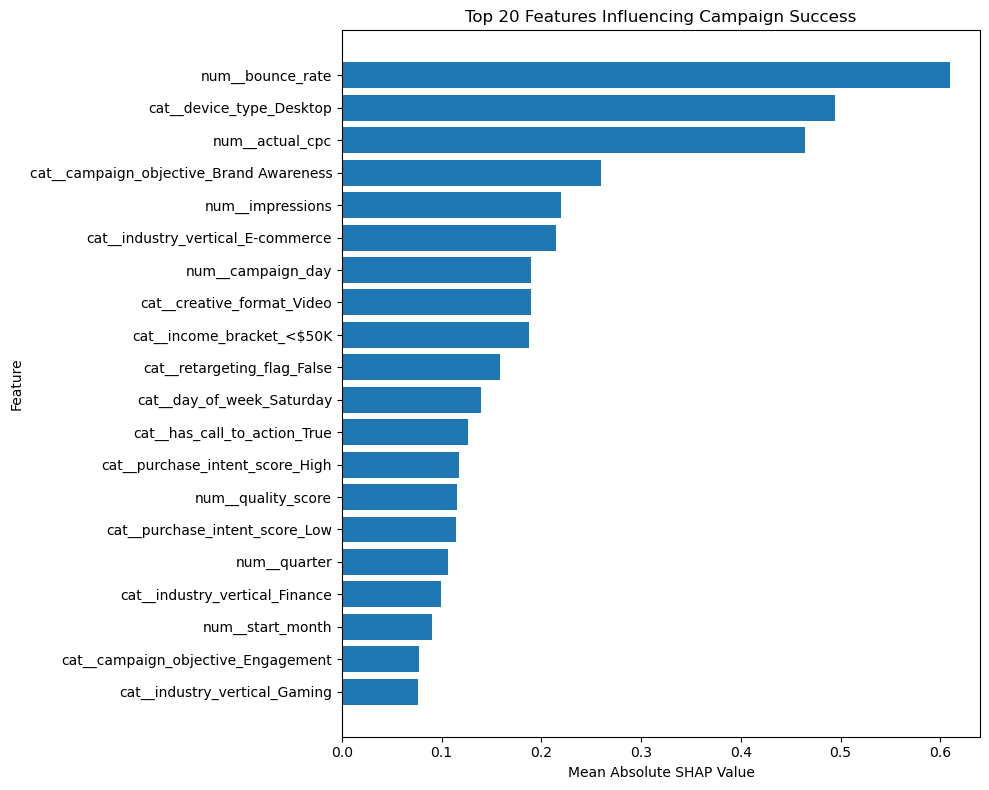

Feature-importance plot saved: c:\Users\ASUS\Desktop\AI Marketing Campaign\results\success_shap_feature_importance.png


In [18]:
# Save the global SHAP feature-importance plot
plt.figure(figsize=(10, 8))

top_features = shap_importance.head(20).sort_values(
    by="Mean_Absolute_SHAP"
)

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 20 Features Influencing Campaign Success")
plt.tight_layout()

plot_path = results_dir / "success_shap_feature_importance.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Feature-importance plot saved:", plot_path)

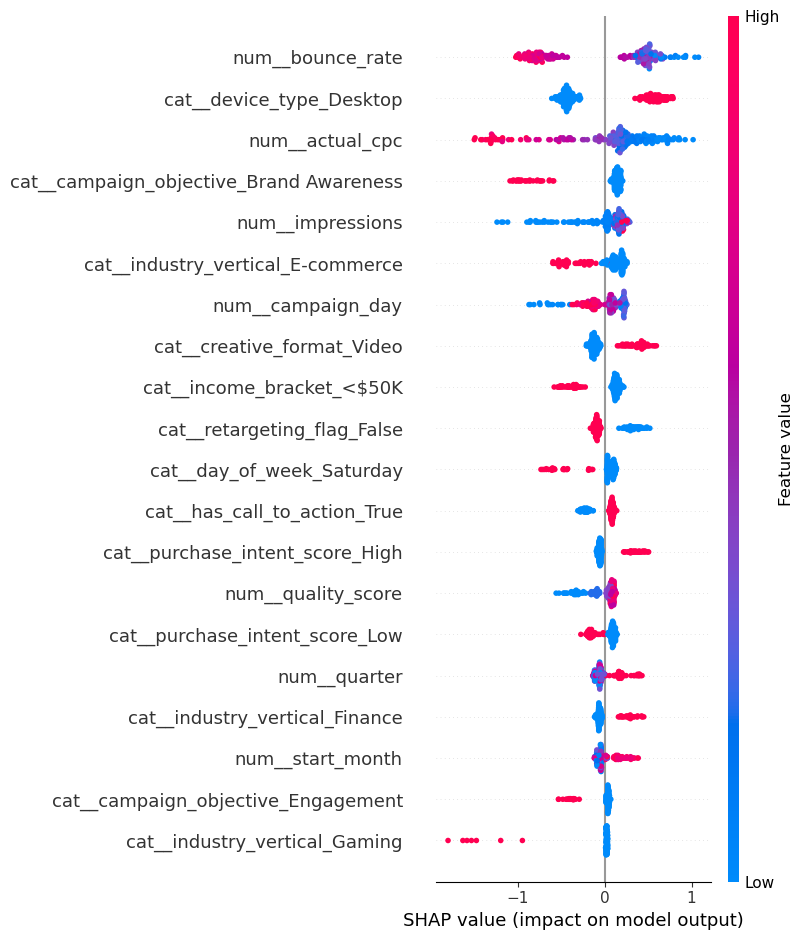

SHAP summary plot saved: c:\Users\ASUS\Desktop\AI Marketing Campaign\results\success_shap_summary_plot.png


In [19]:
# Save the SHAP summary plot
plt.figure()

shap.summary_plot(
    shap_values.values,
    X_explain,
    max_display=20,
    show=False
)

summary_path = results_dir / "success_shap_summary_plot.png"

plt.savefig(
    summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP summary plot saved:", summary_path)

In [20]:
summary_path = results_dir / "success_shap_summary_plot.png"

print("Summary plot exists:", summary_path.exists())
print("Summary plot path:", summary_path)

Summary plot exists: True
Summary plot path: c:\Users\ASUS\Desktop\AI Marketing Campaign\results\success_shap_summary_plot.png


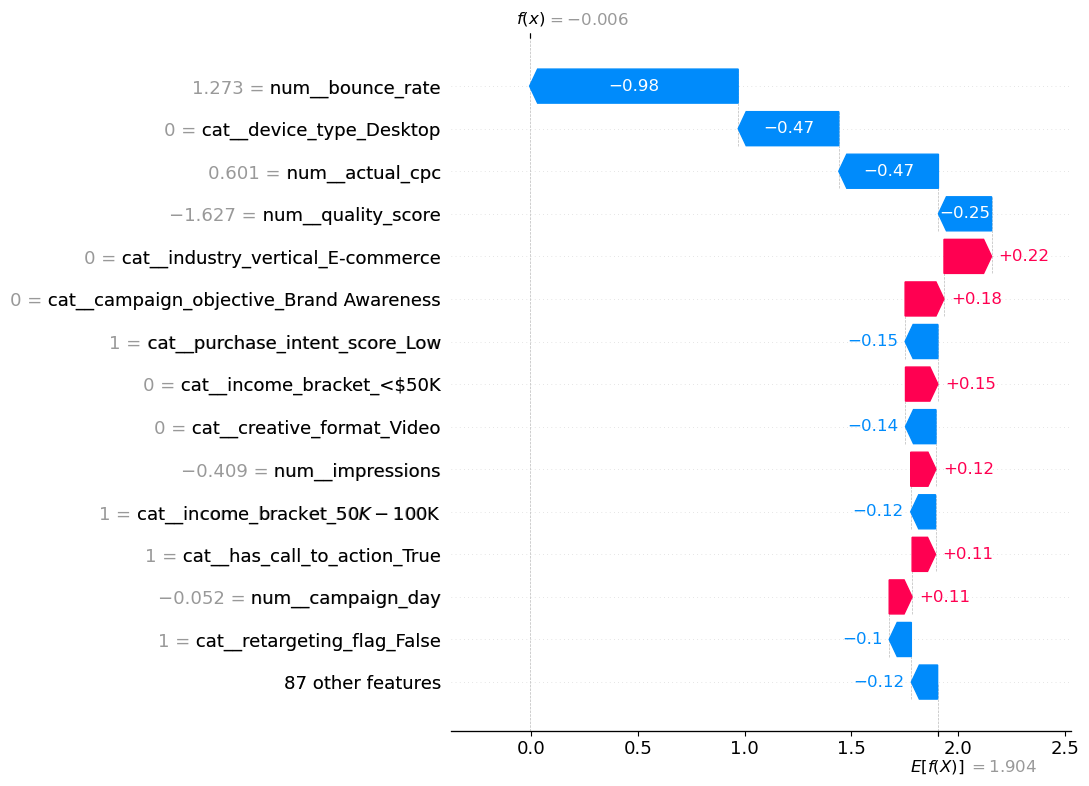

Waterfall plot saved: c:\Users\ASUS\Desktop\AI Marketing Campaign\results\success_shap_campaign_6252_waterfall.png
File exists: True


In [21]:
# Save the individual campaign SHAP waterfall plot
waterfall_path = results_dir / "success_shap_campaign_6252_waterfall.png"

shap.plots.waterfall(
    campaign_shap,
    max_display=15,
    show=False
)

plt.savefig(
    waterfall_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Waterfall plot saved:", waterfall_path)
print("File exists:", waterfall_path.exists())